# Sales Forecasting using Moving Average

## Objective
Forecast future monthly sales using historical sales data from the Superstore dataset.

### Steps
- Load Dataset
- Data Preprocessing
- Monthly Sales Aggregation
- Moving Average Forecast
- Visualization
- Business Insights

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/processed/processed_superstore.csv")

df["Order Date"] = pd.to_datetime(df["Order Date"])

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Order Weekday,Shipping Days,Profit Margin (%),Sales Per Unit,Discount Category,Order Size,Sales Category,Profit Category,Shipping Speed,Customer Lifetime Value
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Tuesday,3,16.00,130.98,No Discount,Small,Medium Sales,Low Profit,Standard,1148.7800
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Tuesday,3,30.00,243.98,No Discount,Medium,High Sales,Medium Profit,Standard,1148.7800
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Sunday,4,47.00,7.31,No Discount,Small,Low Sales,Low Profit,Standard,1119.4830
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Sunday,7,-40.00,191.52,Medium,Medium,High Sales,Loss,Slow,2602.5755
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Sunday,7,11.25,11.18,Low,Small,Low Sales,Low Profit,Slow,2602.5755


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 36 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Row ID                   9994 non-null   int64         
 1   Order ID                 9994 non-null   str           
 2   Order Date               9994 non-null   datetime64[us]
 3   Ship Date                9994 non-null   str           
 4   Ship Mode                9994 non-null   str           
 5   Customer ID              9994 non-null   str           
 6   Customer Name            9994 non-null   str           
 7   Segment                  9994 non-null   str           
 8   Country                  9994 non-null   str           
 9   City                     9994 non-null   str           
 10  State                    9994 non-null   str           
 11  Postal Code              9994 non-null   int64         
 12  Region                   9994 non-null   str 

In [4]:
df.describe()

,Row ID,Order Date,Postal Code,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Quarter,Order Day,Shipping Days,Profit Margin (%),Sales Per Unit,Customer Lifetime Value
count,9994.000000,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,55190.379428,229.858001,3.789574,0.156203,28.656896,2015.722233,7.809686,2.882329,15.468481,3.958175,12.031390,60.918928,3593.694483
min,1.000000,2014-01-03 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,2014.000000,1.000000,1.000000,1.000000,0.000000,-275.000000,0.340000,4.833000
25%,2499.250000,2015-05-23 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750,2015.000000,5.000000,2.000000,8.000000,3.000000,7.500000,5.470000,1669.135000
50%,4997.500000,2016-06-26 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500,2016.000000,9.000000,3.000000,15.000000,4.000000,27.000000,16.270000,2874.338000
75%,7495.750000,2017-05-14 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000,2017.000000,11.000000,4.000000,23.000000,5.000000,36.250000,63.940000,4715.466000
max,9994.000000,2017-12-30 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000,2017.000000,12.000000,4.000000,31.000000,7.000000,50.000000,3773.080000,25043.050000
std,2885.163629,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108,1.123555,3.284654,1.058086,8.748327,1.747567,46.675436,142.927476,2837.907488


In [5]:
monthly_sales = (
    df.groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
      .sum()
      .reset_index()
)

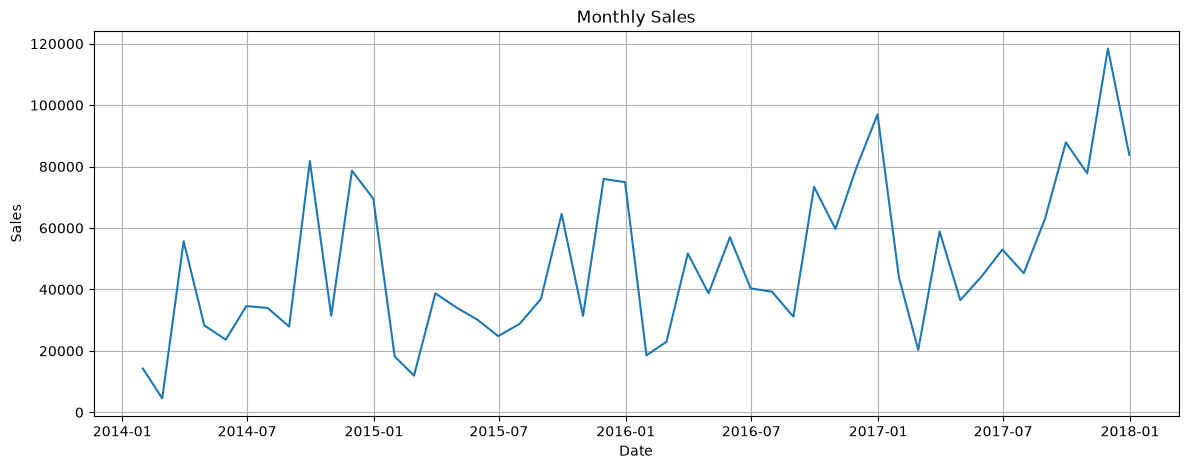

In [6]:
plt.figure(figsize=(14,5))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"]
)

plt.title("Monthly Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)

plt.show()

In [7]:
window = 3

forecast = monthly_sales["Sales"].rolling(window).mean()

monthly_sales["Moving Average"] = forecast

monthly_sales.tail()

,Order Date,Sales,Moving Average
43,2017-08-31,63120.8880,53789.009900
44,2017-09-30,87866.6520,65417.318667
45,2017-10-31,77776.9232,76254.821067
46,2017-11-30,118447.8250,94697.133400
47,2017-12-31,83829.3188,93351.355667


In [8]:
future_sales = []

history = monthly_sales["Sales"].tolist()

for i in range(12):
    value = np.mean(history[-3:])
    future_sales.append(value)
    history.append(value)

In [9]:
future_dates = pd.date_range(
    monthly_sales["Order Date"].max(),
    periods=13,
    freq="ME"
)[1:]

In [10]:
forecast_df = pd.DataFrame({
    "Date":future_dates,
    "Forecast Sales":future_sales
})

forecast_df

,Date,Forecast Sales
0,2018-01-31,93351.355667
1,2018-02-28,98542.833156
2,2018-03-31,91907.835874
3,2018-04-30,94600.674899
4,2018-05-31,95017.114643
5,2018-06-30,93841.875139
6,2018-07-31,94486.554893
7,2018-08-31,94448.514892
8,2018-09-30,94258.981641
9,2018-10-31,94398.017142


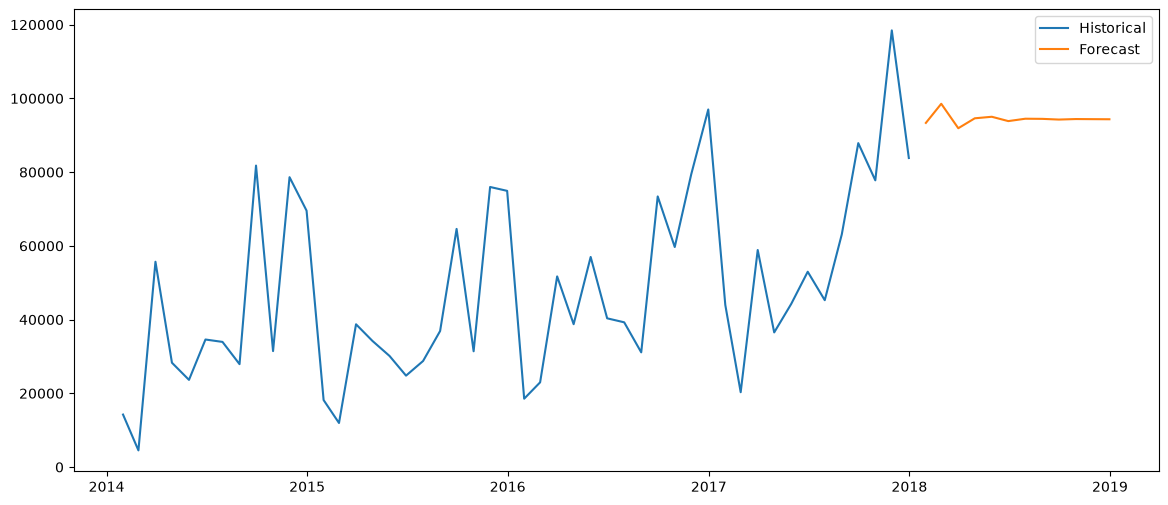

In [11]:
plt.figure(figsize=(14,6))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    label="Historical"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Forecast Sales"],
    label="Forecast"
)

plt.legend()

plt.show()

## Conclusion

• Monthly sales show an increasing trend.

• Moving Average provides a simple forecasting approach.

• Forecast indicates stable sales growth.

• Can be replaced with Prophet or ARIMA for higher accuracy.